<a href="https://colab.research.google.com/github/AnhFmastDzzz/Deep-learning-class/blob/main/23520047_Lab03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BÀI THỰC HÀNH 3: MẠNG NEURAL HỒI QUY CHO BÀI TOÁN PHÂN LOẠI VĂN BẢN VÀ GÁN NHÃN CHUỖI

Bộ dữ liệu sử dụng: [UIT-VSFC](https://drive.google.com/drive/folders/1rdcXNGt_3-QUvV8EtSvVsLMVeHmk6Yqk?usp=drive_link) và [PhoNERT](https://github.com/VinAIResearch/PhoNER_COVID19).


### Bài 1: Xây dựng mạng LSTM gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [1]:
#cai dat thu vien
%pip install --use-pep517 torch numpy pandas matplotlib scikit-learn seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16250 sha256=0473e4fef279f0705da741e6790a19dc1988b53427089ec2dae8cb324f111d7e
  Stored in directory: /root/.cache/pip/wheels/14/cf/a7/8f28ef376d707ff10e3922899482a2f23ef3002f8a952f47ac
Successfully built seqeval


In [2]:
#Kiểm tra môi trường và chọn cấu hình

import copy, hashlib, json, random, time, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import (
    pad_sequence, pack_padded_sequence, pad_packed_sequence,
)
from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report, f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from seqeval.metrics import f1_score as entity_f1
from seqeval.metrics import classification_report as entity_report
from seqeval.scheme import IOB2
import matplotlib.pyplot as plt

def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Phần C: emb=300, hidden=256, layers=5, epochs=10, ner_epochs=10
cfg = dict(emb=300, hidden=256, layers=5, epochs=10, ner_epochs=10,
           batch=32, dropout=0.3, lr=1e-3)
base = Path.cwd()
LAB = base / "Lab3" if (base / "Lab3").is_dir() else base
DATA = LAB / "data"
ART = LAB / "artifacts"
ART.mkdir(parents=True, exist_ok=True)
print("PyTorch:", torch.__version__, "| Thiết bị:", device)
print("Cấu hình:", cfg)

PyTorch: 2.14.1+cu130 | Thiết bị: cuda
Cấu hình: {'emb': 300, 'hidden': 256, 'layers': 5, 'epochs': 10, 'ner_epochs': 10, 'batch': 32, 'dropout': 0.3, 'lr': 0.001}


In [3]:
#Tải dữ liệu và xác nhận đúng phiên bản
# Tải một lần; không đọc nội dung test để chọn mô hình.
DATA_FILES = [('uit-vsfc/UIT-VSFC-train.json', 'https://drive.google.com/uc?export=download&id=1eJdEStCQBf3GtbOIQfIR2iS-Wb3nlfJX', 'e41e65672f2ade65ee8d2d394659a2bfeabbce987f0d2ad9e19998068a78fc1e'), ('uit-vsfc/UIT-VSFC-dev.json', 'https://drive.google.com/uc?export=download&id=1UWbzHFeUPu4AuofOEy0Fo0SFotVZHzUe', 'ab781a38209c17e640e077f83d82ecb9ea4f3469e63fc6ec2a232b0da6fbe823'), ('uit-vsfc/UIT-VSFC-test.json', 'https://drive.google.com/uc?export=download&id=1g4imdabNbswIu91K6zKFGalkjDBBqaQq', '14a6c5697907084086551a17c76e908dad88f2dc3b8be720c9880c8fc1212aa6'), ('phoner/train_syllable.json', 'https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/train_syllable.json', 'fb4097f6ac956a03e484319898db0dafc7283c135cd7888f803ad26a5a253419'), ('phoner/dev_syllable.json', 'https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/dev_syllable.json', 'c74393fb5d1547d51ddda175830892ca62a7efa2d93291b21a35cb21bfee612e'), ('phoner/test_syllable.json', 'https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/test_syllable.json', '4b677028d6db5e1dab74d727d88b719454da60cfeaba681d9ee401fc83b04c77')]
for rel, url, expected in DATA_FILES:
    path = DATA / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        with urllib.request.urlopen(url, timeout=90) as response:
            content = response.read()
        if hashlib.sha256(content).hexdigest() != expected:
            raise ValueError("Nguồn tải đã đổi hoặc trả về HTML: " + rel)
        path.write_bytes(content)
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    if actual != expected:
        raise ValueError("Checksum không khớp: " + rel)
print("Đã xác nhận 6/6 tệp dữ liệu bằng SHA-256.")

Đã xác nhận 6/6 tệp dữ liệu bằng SHA-256.


In [4]:
#Đọc JSON, JSON Lines và kiểm tra nhãn
LABELS = ["negative", "neutral", "positive"]
label_to_id = {name: i for i, name in enumerate(LABELS)}
vsfc, ner = {}, {}
for split in ["train", "dev", "test"]:
    path = DATA / "uit-vsfc" / f"UIT-VSFC-{split}.json"
    vsfc[split] = json.loads(path.read_text(encoding="utf-8-sig"))
    assert all(r["sentiment"] in LABELS for r in vsfc[split])
    path = DATA / "phoner" / f"{split}_syllable.json"
    ner[split] = [json.loads(line) for line in
                  path.read_text(encoding="utf-8-sig").splitlines()
                  if line.strip()]
    assert all(len(r["words"]) == len(r["tags"]) > 0
               for r in ner[split])
    print(split, "| UIT-VSFC:", len(vsfc[split]),
          "| PhoNER:", len(ner[split]))
counts = Counter(r["sentiment"] for r in vsfc["train"])
print("Sentiment train:", {k: counts[k] for k in LABELS})
print("Kiểm tra token/nhãn PhoNER: PASS")

train | UIT-VSFC: 11426 | PhoNER: 5027
dev | UIT-VSFC: 1583 | PhoNER: 2000
test | UIT-VSFC: 3166 | PhoNER: 3000
Sentiment train: {'negative': 5325, 'neutral': 458, 'positive': 5643}
Kiểm tra token/nhãn PhoNER: PASS


In [5]:
#Tự kiểm tra trước khi đến lớp
assert [len(vsfc[s]) for s in vsfc] == [11426, 1583, 3166]
assert [len(ner[s]) for s in ner] == [5027, 2000, 3000]
assert set(counts) == set(LABELS)
print("3/3 kiểm tra chuẩn bị: PASS")

3/3 kiểm tra chuẩn bị: PASS


In [6]:
#B.1. Từ trạng thái ẩn đến RNN nhiều lớp
#Tính trạng thái ẩn qua ba bước thời gian
h = torch.tensor(0.0)
for t, x_t in enumerate([1.0, 1.0, 1.0], start=1):
    h = torch.tanh(0.5 * x_t + 0.8 * h)
    print(f"h_{t} = {h.item():.6f}")
print(f"0.5**50 = {0.5**50:.3e}")

h_1 = 0.462117
h_2 = 0.701218
h_3 = 0.786037
0.5**50 = 8.882e-16


In [7]:
#Đối chiếu output, h_n và c_n
seed_all()
toy = torch.randn(3, 5, 8)
for name, cls in [("RNN", nn.RNN), ("GRU", nn.GRU),
                  ("LSTM", nn.LSTM)]:
    layer = cls(8, 16, num_layers=2, batch_first=True)
    output, state = layer(toy)
    hidden = state[0] if name == "LSTM" else state
    print(name, "output:", tuple(output.shape),
          "h_n:", tuple(hidden.shape),
          "params:", sum(p.numel() for p in layer.parameters()))
bi = nn.LSTM(8, 16, num_layers=2,
             bidirectional=True, batch_first=True)
output, (h_n, c_n) = bi(toy)
print("BiLSTM:", tuple(output.shape), tuple(h_n.shape),
      tuple(c_n.shape))

RNN output: (3, 5, 16) h_n: (2, 3, 16) params: 960
GRU output: (3, 5, 16) h_n: (2, 3, 16) params: 2880
LSTM output: (3, 5, 16) h_n: (2, 3, 16) params: 3840
BiLSTM: (3, 5, 32) (4, 3, 16) (4, 3, 16)


In [8]:
#B.2. Từ văn bản đến batch embedding
#Xây từ điển từ tập train
PAD, UNK = 0, 1
def tokenize(text):
    return text.lower().split()

def build_vocab(sequences, min_freq=2):
    freq = Counter(t for tokens in sequences for t in tokens)
    tokens = sorted(t for t, n in freq.items() if n >= min_freq)
    return {"<pad>": PAD, "<unk>": UNK,
            **{t: i + 2 for i, t in enumerate(tokens)}}

vocab = build_vocab(tokenize(r["sentence"])
                    for r in vsfc["train"])
def encode(tokens, mapping):
    # TODO 1: Dùng từ điển; từ chưa thấy chuyển thành UNK.
    return [mapping.get(t, UNK) for t in tokens] or [UNK]

example = tokenize("giảng viên dạy rất hay")
print("Token minh họa:", example)
print("Chỉ số:", encode(example, vocab))
print("Kích thước từ điển train:", len(vocab))
assert vocab["<pad>"] == 0 and vocab["<unk>"] == 1

Token minh họa: ['giảng', 'viên', 'dạy', 'rất', 'hay']
Chỉ số: [394, 1313, 337, 978, 436]
Kích thước từ điển train: 1535


In [9]:
#Tạo batch có độ dài khác nhau
def cls_rows(rows):
    return [(encode(tokenize(r["sentence"]), vocab),
             label_to_id[r["sentiment"]]) for r in rows]

def collate_cls(rows):
    ids = [torch.tensor(x, dtype=torch.long) for x, _ in rows]
    lengths = torch.tensor([len(x) for x in ids])
    x = pad_sequence(ids, batch_first=True, padding_value=PAD)
    y = torch.tensor([label for _, label in rows])
    return x, lengths, y

demo_rows = [(encode(tokenize(t), vocab), y) for t, y in [
    ("dạy hay", 2), ("nội dung còn khó hiểu", 0),
    ("bình thường", 1)]]
x, lengths, y = collate_cls(demo_rows)
print("ids shape:", tuple(x.shape), "| lengths:", lengths.tolist())
print("nhãn:", y.tolist())
emb = nn.Embedding(len(vocab), 8, padding_idx=PAD)
print("embedding shape:", tuple(emb(x).shape))
print("Vector PAD bằng 0:", bool(torch.all(emb.weight[PAD] == 0)))

ids shape: (3, 5) | lengths: [2, 5, 2]
nhãn: [2, 0, 1]
embedding shape: (3, 5, 8)
Vector PAD bằng 0: True


In [10]:
#B.3. Baseline và macro-F1 cho phân loại cảm xúc
#Chạy hai baseline trên UIT-VSFC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

train_text = [r["sentence"] for r in vsfc["train"]]
dev_text = [r["sentence"] for r in vsfc["dev"]]
train_y = [label_to_id[r["sentiment"]] for r in vsfc["train"]]
dev_y = [label_to_id[r["sentiment"]] for r in vsfc["dev"]]
majority = Counter(train_y).most_common(1)[0][0]
baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                    token_pattern=r"(?u)\b\w+\b"),
    LogisticRegression(max_iter=1000, random_state=42),
)
baseline.fit(train_text, train_y)
base_pred = baseline.predict(dev_text)
print("Majority dev macro-F1:", round(f1_score(
    dev_y, [majority] * len(dev_y), labels=[0, 1, 2],
    average="macro", zero_division=0), 4))
print("TF-IDF dev macro-F1:", round(f1_score(
    dev_y, base_pred, labels=[0, 1, 2],
    average="macro", zero_division=0), 4))
print(classification_report(dev_y, base_pred, labels=[0, 1, 2],
                            target_names=LABELS,
                            digits=4, zero_division=0))

Majority dev macro-F1: 0.2247
TF-IDF dev macro-F1: 0.6894
              precision    recall  f1-score   support

    negative     0.8855    0.9546    0.9188       705
     neutral     0.8182    0.1233    0.2143        73
    positive     0.9310    0.9391    0.9351       805

    accuracy                         0.9084      1583
   macro avg     0.8782    0.6723    0.6894      1583
weighted avg     0.9056    0.9084    0.8946      1583



In [11]:
#B.4. LSTM: packing, huấn luyện và đánh giá
#Cài mô hình phân loại dùng packing
class TextClassifier(nn.Module):
    def __init__(self, vocab_size, kind="LSTM", emb=64,
                 hidden=64, layers=1, dropout=0.3,
                 bidirectional=False):
        super().__init__()
        self.kind = kind
        self.bidirectional = bidirectional
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        self.rnn = cls(emb, hidden, layers, batch_first=True,
                       bidirectional=bidirectional,
                       dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), 3)

    def forward(self, ids, lengths):
        embedded = self.emb(ids)
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True,
            enforce_sorted=False,
        )
        _, state = self.rnn(packed)
        h = state[0] if self.kind == "LSTM" else state
        vec = torch.cat([h[-2], h[-1]], dim=1) \
              if self.bidirectional else h[-1]
        return self.fc(self.drop(vec))

model_args = {k: cfg[k] for k in
              ["emb", "hidden", "layers", "dropout"]}
seed_all()
lstm = TextClassifier(len(vocab), **model_args).to(device)
print("logits shape:", tuple(lstm(x.to(device), lengths).shape))
print("Số tham số:", sum(p.numel() for p in lstm.parameters()))

logits shape: (3, 3)
Số tham số: 3138007


In [12]:
#Kiểm tra cùng câu với hai độ dài đệm
sentence_ids = encode(tokenize("giảng viên dạy hay"), vocab)
def padded(length):
    return torch.tensor([sentence_ids +
                         [PAD] * (length - len(sentence_ids))],
                         device=device)

lens = torch.tensor([len(sentence_ids)])
lstm.eval()
with torch.no_grad():
    a = lstm(padded(8), lens)
    b = lstm(padded(64), lens)
    raw_a, _ = lstm.rnn(lstm.emb(padded(8)))
    raw_b, _ = lstm.rnn(lstm.emb(padded(64)))
torch.testing.assert_close(a, b, atol=1e-6, rtol=1e-5)
print("Packing, đệm 8 và 64: PASS")
print("Sai khác khi dùng output[:, -1] không packing:",
      round((raw_a[:, -1] - raw_b[:, -1]).abs().max().item(), 6))

Packing, đệm 8 và 64: PASS
Sai khác khi dùng output[:, -1] không packing: 0.002775


In [13]:
#Chuẩn bị DataLoader
cls_train = cls_rows(vsfc["train"])
cls_dev = cls_rows(vsfc["dev"])
def cls_loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg["batch"],
                      shuffle=shuffle, collate_fn=collate_cls,
                      generator=torch.Generator().manual_seed(42))

dev_loader = cls_loader(cls_dev)
print("Số câu train/dev:",
      len(cls_train), len(cls_dev))

Số câu train/dev: 11426 1583


In [14]:
#Viết vòng lặp huấn luyện và chọn checkpoint
def evaluate_cls(model, loader):
    model.eval()
    true, pred = [], []
    with torch.no_grad():
        for ids, lengths, labels in loader:
            logits = model(ids.to(device), lengths)
            true.extend(labels.tolist())
            pred.extend(logits.argmax(-1).cpu().tolist())
    score = f1_score(true, pred, labels=[0, 1, 2],
                     average="macro", zero_division=0)
    return score, true, pred

def fit_cls(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    criterion = nn.CrossEntropyLoss()
    best, best_state, history = -1.0, None, []
    loader = cls_loader(cls_train, shuffle=True)
    for epoch in range(1, cfg["epochs"] + 1):
        start = time.perf_counter()
        model.train()
        total_loss, total = 0.0, 0
        for ids, lengths, labels in loader:
            ids, labels = ids.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(ids, lengths), labels)
            loss.backward()
            # TODO 3: Chặn chuẩn gradient sau backward, trước step.
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            total_loss += loss.item() * labels.numel()
            total += labels.numel()
        seconds = time.perf_counter() - start
        score, _, _ = evaluate_cls(model, dev_loader)
        history.append(dict(epoch=epoch, loss=total_loss / total,
                            dev_f1=score, seconds=seconds))
        if score > best:
            best, best_state = score, copy.deepcopy(model.state_dict())
        print(f"{name} epoch {epoch}: loss={total_loss/total:.4f} "
              f"dev_macro_F1={score:.4f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART / f"{name}.pt")
    return history
print("Đã định nghĩa fit_cls và evaluate_cls.")

Đã định nghĩa fit_cls và evaluate_cls.


In [15]:
#Huấn luyện LSTM và đọc F1 từng lớp
seed_all()
lstm = TextClassifier(len(vocab), kind="LSTM", **model_args).to(device)
lstm_history = fit_cls(lstm, "lstm")
lstm_score, y_true, y_pred = evaluate_cls(lstm, dev_loader)
print(classification_report(y_true, y_pred, labels=[0, 1, 2],
                            target_names=LABELS,
                            digits=4, zero_division=0))

lstm epoch 1: loss=0.4550 dev_macro_F1=0.6183
lstm epoch 2: loss=0.2799 dev_macro_F1=0.7355
lstm epoch 3: loss=0.2370 dev_macro_F1=0.7936
lstm epoch 4: loss=0.2011 dev_macro_F1=0.7944
lstm epoch 5: loss=0.1718 dev_macro_F1=0.7831
lstm epoch 6: loss=0.1466 dev_macro_F1=0.7982
lstm epoch 7: loss=0.1292 dev_macro_F1=0.7850
lstm epoch 8: loss=0.1104 dev_macro_F1=0.7912
lstm epoch 9: loss=0.1026 dev_macro_F1=0.7814
lstm epoch 10: loss=0.0873 dev_macro_F1=0.7943
              precision    recall  f1-score   support

    negative     0.9255    0.9333    0.9294       705
     neutral     0.5455    0.4932    0.5180        73
    positive     0.9467    0.9478    0.9472       805

    accuracy                         0.9204      1583
   macro avg     0.8059    0.7914    0.7982      1583
weighted avg     0.9187    0.9204    0.9195      1583



### Bài 2: Xây dựng mạng GRU gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [16]:
#Huấn luyện GRU với cùng cấu hình
seed_all()
gru = TextClassifier(len(vocab), kind="GRU", **model_args).to(device)
gru_history = fit_cls(gru, "gru")
gru_score, _, _ = evaluate_cls(gru, dev_loader)
comparison = pd.DataFrame([
    {"model": name, "dev_macro_F1": score,
     "parameters": sum(p.numel() for p in model.parameters()),
     "seconds_per_epoch": np.mean([r["seconds"] for r in history])}
    for name, model, score, history in [
        ("LSTM", lstm, lstm_score, lstm_history),
        ("GRU", gru, gru_score, gru_history)]
])
comparison.to_csv(ART / "classification_dev.csv", index=False)
print(comparison.drop(columns="seconds_per_epoch").to_string(index=False))
print("Đã lưu thời gian/epoch trong classification_dev.csv.")

gru epoch 1: loss=0.3875 dev_macro_F1=0.7408
gru epoch 2: loss=0.2627 dev_macro_F1=0.7293
gru epoch 3: loss=0.2220 dev_macro_F1=0.7670
gru epoch 4: loss=0.1845 dev_macro_F1=0.7789
gru epoch 5: loss=0.1574 dev_macro_F1=0.7611
gru epoch 6: loss=0.1375 dev_macro_F1=0.7700
gru epoch 7: loss=0.1172 dev_macro_F1=0.7941
gru epoch 8: loss=0.1033 dev_macro_F1=0.7581
gru epoch 9: loss=0.0941 dev_macro_F1=0.7950
gru epoch 10: loss=0.0817 dev_macro_F1=0.7858
model  dev_macro_F1  parameters
 LSTM      0.798201     3138007
  GRU      0.795001     2468823
Đã lưu thời gian/epoch trong classification_dev.csv.


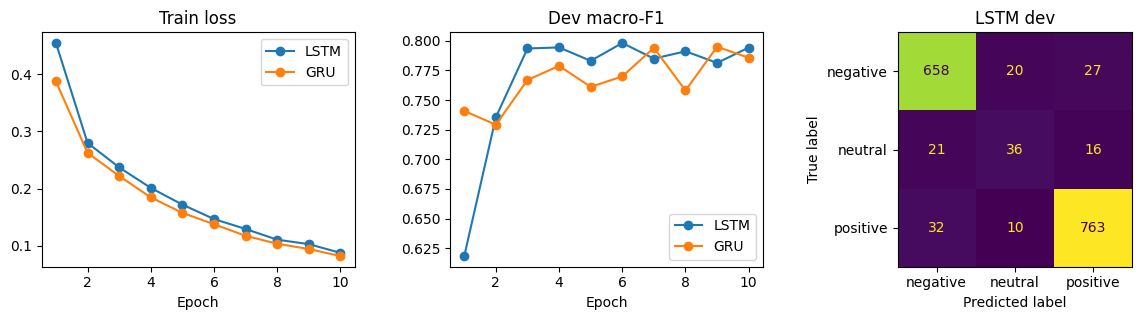

Đã lưu classification.png.


In [17]:
#Vẽ đường học và ma trận nhầm lẫn
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for name, history in [("LSTM", lstm_history), ("GRU", gru_history)]:
    axes[0].plot([r["epoch"] for r in history],
                 [r["loss"] for r in history], marker="o", label=name)
    axes[1].plot([r["epoch"] for r in history],
                 [r["dev_f1"] for r in history], marker="o", label=name)
axes[0].set_title("Train loss")
axes[1].set_title("Dev macro-F1")
for ax in axes[:2]:
    ax.set_xlabel("Epoch")
    ax.legend()
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[0, 1, 2], display_labels=LABELS,
    ax=axes[2], colorbar=False,
)
axes[2].set_title("LSTM dev")
fig.tight_layout()
fig.savefig(ART / "classification.png", dpi=150)
plt.show()
print("Đã lưu classification.png.")

### Bài 3: Xây dựng kiến trúc Encoder trong đó Encoder gồm 5 lớp BiLSTM với hidden size là 256 cho bài toán nhận diện thực thể (Name Entity Recognition). Huấn luyện mô hình trên bộ dữ liệu PhoNER và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [18]:
#Phân biệt F1 theo token và theo thực thể
gold = [["O", "B-LOCATION", "I-LOCATION", "O"]]
guess = [["O", "B-LOCATION", "O", "O"]]
token_accuracy = np.mean(np.array(gold[0]) == np.array(guess[0]))
print("Token accuracy:", token_accuracy)
print("Entity F1:", entity_f1(gold, guess, mode="strict", scheme=IOB2))
print("Ví dụ tự tạo: đúng 3/4 token nhưng đúng 0/1 thực thể.")

Token accuracy: 0.75
Entity F1: 0.0
Ví dụ tự tạo: đúng 3/4 token nhưng đúng 0/1 thực thể.


In [19]:
#Mã hóa PhoNER và bỏ qua nhãn đệm
ner_vocab = build_vocab(r["words"] for r in ner["train"])
TAGS = sorted({tag for row in ner["train"] for tag in row["tags"]})
tag_to_id = {tag: i for i, tag in enumerate(TAGS)}
PAD_TAG = -100
assert len(TAGS) == 21
assert all(tag in tag_to_id for split in ["dev", "test"]
           for row in ner[split] for tag in row["tags"])

def ner_rows(rows):
    return [(encode(r["words"], ner_vocab),
             [tag_to_id[t] for t in r["tags"]]) for r in rows]

def collate_ner(rows):
    ids = [torch.tensor(x) for x, _ in rows]
    tags = [torch.tensor(y) for _, y in rows]
    lengths = torch.tensor([len(x) for x in ids])
    return (pad_sequence(ids, batch_first=True, padding_value=PAD),
            lengths,
            pad_sequence(tags, batch_first=True,
                         padding_value=PAD_TAG))

ner_train = ner_rows(ner["train"])
ner_dev = ner_rows(ner["dev"])
def ner_loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg["batch"],
                      shuffle=shuffle, collate_fn=collate_ner,
                      generator=torch.Generator().manual_seed(42))

nx, nl, ny = next(iter(ner_loader(ner_train)))
print("Số nhãn BIO:", len(TAGS), "| PAD_TAG:", PAD_TAG)
print("ids/nhãn:", tuple(nx.shape), tuple(ny.shape))
print("Số câu train/dev:", len(ner_train), len(ner_dev))

Số nhãn BIO: 21 | PAD_TAG: -100
ids/nhãn: (32, 117) (32, 117)
Số câu train/dev: 5027 2000


In [20]:
#Cài BiLSTM cho từng token
class TokenTagger(nn.Module):
    def __init__(self, vocab_size, num_tags, emb=64,
                 hidden=64, layers=1, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.rnn = nn.LSTM(
            emb, hidden, layers, batch_first=True,
            bidirectional=True,
            dropout=dropout if layers > 1 else 0.0,
        )
        self.drop = nn.Dropout(dropout)
        # TODO 4: Ghép hai chiều nên đầu vào Linear có 2H chiều.
        self.fc = nn.Linear(hidden * 2, num_tags)

    def forward(self, ids, lengths):
        packed = pack_padded_sequence(
            self.emb(ids), lengths.cpu(), batch_first=True,
            enforce_sorted=False,
        )
        output, _ = self.rnn(packed)
        output, _ = pad_packed_sequence(
            output, batch_first=True, total_length=ids.size(1),
        )
        return self.fc(self.drop(output))

seed_all()
tagger = TokenTagger(len(ner_vocab), len(TAGS), **model_args).to(device)
# TODO 5: Bỏ qua đúng nhãn đệm -100 khi tính loss.
criterion_ner = nn.CrossEntropyLoss(ignore_index=PAD_TAG)
logits = tagger(nx.to(device), nl)
loss = criterion_ner(logits.reshape(-1, len(TAGS)),
                     ny.to(device).reshape(-1))
assert logits.shape[:2] == ny.shape
print("logits:", tuple(logits.shape), "| Loss hữu hạn:",
      bool(torch.isfinite(loss)))

logits: (32, 117, 21) | Loss hữu hạn: True


In [21]:
#Kiểm tra padding của BiLSTM và loss
toy_ids = encode(["Ví", "dụ", "tự", "tạo"], ner_vocab)
def padded_ner(n):
    return torch.tensor([toy_ids + [PAD] * (n - len(toy_ids))],
                         device=device)

tagger.eval()
with torch.no_grad():
    n8 = tagger(padded_ner(8), torch.tensor([4]))
    n64 = tagger(padded_ner(64), torch.tensor([4]))
torch.testing.assert_close(n8[:, :4], n64[:, :4],
                           atol=1e-6, rtol=1e-5)
target = torch.tensor([[tag_to_id["O"]] * 4], device=device)
a = criterion_ner(n8[:, :4].reshape(-1, len(TAGS)), target.flatten())
padded_target = torch.cat([
    target, torch.full((1, 4), PAD_TAG, device=device)], dim=1)
b = criterion_ner(n8.reshape(-1, len(TAGS)), padded_target.flatten())
torch.testing.assert_close(a, b)
print("BiLSTM đệm 8/64: PASS | Loss bỏ padding: PASS")

BiLSTM đệm 8/64: PASS | Loss bỏ padding: PASS


In [22]:
#Huấn luyện và đánh giá BiLSTM bằng seqeval
def evaluate_ner(model, loader):
    model.eval()
    true, pred = [], []
    with torch.no_grad():
        for ids, lengths, labels in loader:
            predicted = model(ids.to(device), lengths).argmax(-1).cpu()
            for actual, guessed, length in zip(labels, predicted, lengths):
                n = int(length)
                # TODO 6: Cắt nhãn thật theo độ dài, bỏ PAD_TAG trước khi đổi nhãn.
                true.append([TAGS[int(i)] for i in actual[:n]])
                # TODO 7: Chỉ chấm dự đoán tại token thật.
                pred.append([TAGS[int(i)] for i in guessed[:n]])
    score = entity_f1(true, pred, mode="strict", scheme=IOB2,
                      zero_division=0)
    return score, true, pred

def fit_ner(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    best, best_state, history = -1.0, None, []
    for epoch in range(1, cfg["ner_epochs"] + 1):
        model.train()
        start = time.perf_counter()
        total_loss, tokens = 0.0, 0
        for ids, lengths, labels in ner_loader(ner_train, shuffle=True):
            ids, labels = ids.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(ids, lengths)
            loss = criterion_ner(logits.reshape(-1, len(TAGS)),
                                 labels.reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            count = int((labels != PAD_TAG).sum())
            total_loss += loss.item() * count
            tokens += count
        seconds = time.perf_counter() - start
        score, _, _ = evaluate_ner(model, ner_loader(ner_dev))
        history.append(dict(epoch=epoch, loss=total_loss/tokens,
                            dev_f1=score, seconds=seconds))
        if score > best:
            best, best_state = score, copy.deepcopy(model.state_dict())
        print(f"BiLSTM epoch {epoch}: loss={total_loss/tokens:.4f} "
              f"dev_entity_F1={score:.4f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART / "bilstm_ner.pt")
    return history

ner_history = fit_ner(tagger)
ner_score, ner_true, ner_pred = evaluate_ner(tagger, ner_loader(ner_dev))
print(entity_report(ner_true, ner_pred, mode="strict", scheme=IOB2,
                     digits=4, zero_division=0))

BiLSTM epoch 1: loss=0.6934 dev_entity_F1=0.6760
BiLSTM epoch 2: loss=0.1659 dev_entity_F1=0.8425
BiLSTM epoch 3: loss=0.0872 dev_entity_F1=0.8665
BiLSTM epoch 4: loss=0.0609 dev_entity_F1=0.8861
BiLSTM epoch 5: loss=0.0458 dev_entity_F1=0.8920
BiLSTM epoch 6: loss=0.0398 dev_entity_F1=0.8982
BiLSTM epoch 7: loss=0.0300 dev_entity_F1=0.8977
BiLSTM epoch 8: loss=0.0273 dev_entity_F1=0.8957
BiLSTM epoch 9: loss=0.0198 dev_entity_F1=0.9035
BiLSTM epoch 10: loss=0.0163 dev_entity_F1=0.9026
                     precision    recall  f1-score   support

                AGE     0.9208    0.9668    0.9432       361
               DATE     0.9631    0.9692    0.9661      1103
             GENDER     0.8775    0.9567    0.9154       277
                JOB     0.6439    0.6439    0.6439       132
           LOCATION     0.9309    0.9207    0.9258      2737
               NAME     0.6562    0.5585    0.6034       188
       ORGANIZATION     0.8753    0.7895    0.8302       551
         PATIENT_ID 

In [23]:
#Lưu cấu hình, từ điển và nạp lại checkpoint
metadata = dict(
    config=cfg, seed=42, device=str(device),
    torch_version=str(torch.__version__), vocab=vocab,
    labels=LABELS, ner_vocab=ner_vocab, tags=TAGS,
    files=[dict(path=p, url=u, sha256=h) for p, u, h in DATA_FILES],
    histories=dict(lstm=lstm_history, gru=gru_history, ner=ner_history),
)
(ART / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
restored = TextClassifier(len(vocab), **model_args).to(device)
restored.load_state_dict(torch.load(ART / "lstm.pt",
                                     map_location=device, weights_only=True))
restored.eval()
ids, lengths, _ = next(iter(dev_loader))
with torch.no_grad():
    torch.testing.assert_close(restored(ids.to(device), lengths),
                               lstm(ids.to(device), lengths))
print("Nạp lại checkpoint LSTM: PASS")
print("Đã lưu metadata.json và ba checkpoint trong", ART)

Nạp lại checkpoint LSTM: PASS
Đã lưu metadata.json và ba checkpoint trong /content/artifacts


In [24]:
#Chấm test một lần sau khi chốt mô hình
test_loader = cls_loader(cls_rows(vsfc["test"]))
rows = []
for name, model in [("LSTM", lstm), ("GRU", gru)]:
    score, true, pred = evaluate_cls(model, test_loader)
    rows.append(dict(model=name, test_macro_F1=score,
                     test_accuracy=accuracy_score(true, pred)))
    print(name, classification_report(
        true, pred, labels=[0, 1, 2], target_names=LABELS,
        digits=4, zero_division=0))
pred = baseline.predict([r["sentence"] for r in vsfc["test"]])
true = [label_to_id[r["sentiment"]] for r in vsfc["test"]]
rows.append(dict(model="TF-IDF", test_macro_F1=f1_score(
    true, pred, labels=[0, 1, 2], average="macro", zero_division=0),
    test_accuracy=accuracy_score(true, pred)))
pd.DataFrame(rows).to_csv(ART / "classification_test.csv", index=False)
score, true, pred = evaluate_ner(
    tagger, ner_loader(ner_rows(ner["test"])))
report = entity_report(true, pred, mode="strict", scheme=IOB2,
                        digits=4, zero_division=0)
(ART / "ner_test.txt").write_text(report, encoding="utf-8")
print("BiLSTM NER test entity-F1:", round(score, 4))
print(report)

LSTM               precision    recall  f1-score   support

    negative     0.8975    0.9319    0.9143      1409
     neutral     0.4711    0.3413    0.3958       167
    positive     0.9279    0.9233    0.9256      1590

    accuracy                         0.8964      3166
   macro avg     0.7655    0.7322    0.7453      3166
weighted avg     0.8903    0.8964    0.8926      3166

GRU               precision    recall  f1-score   support

    negative     0.9129    0.9375    0.9251      1409
     neutral     0.5333    0.3832    0.4460       167
    positive     0.9287    0.9340    0.9313      1590

    accuracy                         0.9065      3166
   macro avg     0.7917    0.7516    0.7675      3166
weighted avg     0.9008    0.9065    0.9029      3166

BiLSTM NER test entity-F1: 0.8935
                     precision    recall  f1-score   support

                AGE     0.9183    0.9656    0.9414       582
               DATE     0.9570    0.9680    0.9624      1654
           